# Project 12: Ensemble Learning, Bagging vs. Boosting

UML501 Machine Learning Lab, Thapar Institute of Engineering and Technology, Patiala
Lab instructor: Charchit Chandra
Group: _<add member names and roll numbers>_
Dataset: Breast Cancer Wisconsin (Diagnostic)

**Contents**
1. Problem definition and background
2. Dataset documentation
3. Setup and reproducibility
4. EDA (training split only)
5. Preprocessing and split strategy
6. Baseline and proposed methods
7. Experiment 1: main comparison (repeated CV + held-out test)
8. Experiment 2: number of estimators
9. Experiment 3: tree depth
10. Interpretability, failure cases and statistical check
11. Limitations and conclusion
12. References

## 1. Problem definition and background

**Problem.** Compare a single decision tree against a bagging ensemble (Random Forest) and boosting ensembles (AdaBoost, Gradient Boosting) on a binary tumour classification task. The comparison covers generalization, predictive performance and computational cost, and discusses interpretability.

**Research questions**
- **RQ1.** Do Random Forest and the boosting methods beat a single decision tree on unseen data, and is the gap larger than the noise in the estimate?
- **RQ2.** How does performance (and cost) change with the number of estimators for bagging vs boosting?
- **RQ3.** How does tree depth change the train/validation gap for each method?
- **RQ4.** What does each method cost in training time, inference time and model size, and what is lost in interpretability?

**Motivation.** The task is diagnosing a breast mass as malignant or benign from measurements of a fine-needle-aspirate image. A missed malignant case (false negative) is worse than a false alarm, so recall on the malignant class is reported next to accuracy, F1 and ROC-AUC.

**Background (short).**
- *Bagging / Random Forest* trains many deep trees on bootstrap samples (plus random feature subsets at each split) and averages them. The aim is variance reduction: individual trees overfit, but their errors are partly uncorrelated (Breiman, 1996; 2001).
- *AdaBoost* trains weak learners (stumps by default) in sequence, re-weighting the samples that earlier learners got wrong, and combines them by a weighted vote (Freund & Schapire, 1997).
- *Gradient Boosting* adds shallow trees in sequence, each fit to the negative gradient of the loss of the current ensemble, with a learning rate that shrinks each step (Friedman, 2001). The usual expectation is that boosting reduces bias and bagging reduces variance. This notebook tests what actually happens on this dataset instead of assuming it.

## 2. Dataset documentation

| Item | Detail |
|---|---|
| Name | Breast Cancer Wisconsin (Diagnostic), WDBC |
| Source | UCI Machine Learning Repository, Wolberg, Street and Mangasarian (1995), DOI 10.24432/C5DW2B. The copy used here is the one bundled with scikit-learn (`sklearn.datasets.load_breast_cancer`), so no download is needed. |
| Usage terms | Listed on the UCI page as CC BY 4.0; check the page before redistributing. |
| Samples | 569 |
| Features | 30 numeric: 10 nuclei measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each as mean, standard error and "worst" (mean of the three largest values) |
| Target | Diagnosis: malignant or benign |

**Label convention.** scikit-learn encodes malignant as 0 and benign as 1. We flip it so **malignant = 1 is the positive class**. Precision, recall and F1 below are therefore all about detecting malignant tumours.

**Limitations of the data**
- Small (569 rows) and from a single institution, so results may not transfer to other scanners or populations.
- Features are hand-engineered from images, not raw images.
- The bundled copy has no patient ID, so we cannot check whether several samples come from the same patient. If they do, random splits could be slightly optimistic.
- Many features are strongly correlated (radius, perimeter and area measure nearly the same thing). This matters for feature-importance interpretation.
- With a test set of about 114 samples, one misclassified sample moves accuracy by about 0.9 points. Small differences between models are not reliable, which is why we also use repeated cross-validation.

## 3. Setup and reproducibility

In [1]:
import os, time, pickle, platform, warnings, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy.stats import wilcoxon, spearmanr
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

COLORS = {"Decision Tree": "#7f7f7f", "Random Forest": "#2a9d8f",
          "AdaBoost": "#e76f51", "Gradient Boosting": "#264653"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

env = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
    "platform": platform.platform(), "cpu_count": os.cpu_count(), "seed": SEED,
}
with open("results/environment.txt", "w") as f:
    for k, v in env.items():
        f.write(f"{k}: {v}\n")
for k, v in env.items():
    print(f"{k:13s} {v}")

python        3.13.16
numpy         2.5.3
pandas        3.0.5
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.11.2
seaborn       0.13.2
platform      Linux-6.18.44-fc-v139-x86_64-with-glibc2.39
cpu_count     2
seed          42


## 4. EDA (training split only)

The data is split first (section 5 explains how) and all EDA that could influence modelling decisions is done on the **training** portion only. Only the basic dataset description uses all 569 rows.

In [2]:
bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = (bunch.target == 0).astype(int).rename("malignant")   # 1 = malignant (positive class)

print("shape:", X.shape)
print("missing values:", int(X.isna().sum().sum()))
print("duplicate rows:", int(X.duplicated().sum()))
print("dtypes:", X.dtypes.unique().tolist())
print("class counts (full data):")
print(y.map({0: "benign", 1: "malignant"}).value_counts().to_string())

shape: (569, 30)
missing values: 0
duplicate rows: 0
dtypes: [dtype('float64')]
class counts (full data):
malignant
benign       357
malignant    212


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("train:", X_train.shape, "malignant share:", round(y_train.mean(), 3))
print("test :", X_test.shape, "malignant share:", round(y_test.mean(), 3))

train: (455, 30) malignant share: 0.374
test : (114, 30) malignant share: 0.368


**EDA 1: class balance and feature scales.**

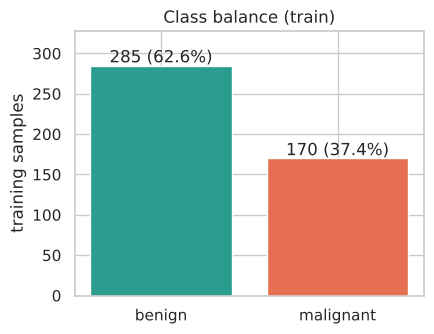

feature scale range (min of means -> max of means): 0.0038 -> 890.6


,min,max,mean,std
fractal dimension error,0.000895,0.02984,0.003766,0.002632
smoothness error,0.001713,0.03113,0.006895,0.002855
concave points error,0.000000,0.05279,0.011691,0.006289
worst perimeter,50.410000,251.20000,107.860484,34.176019
mean area,143.500000,2501.00000,659.578242,360.418686
worst area,185.200000,4254.00000,890.569231,582.346181


In [4]:
counts = y_train.map({0: "benign", 1: "malignant"}).value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(counts.index, counts.values, color=["#2a9d8f", "#e76f51"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 4, f"{v} ({v / len(y_train):.1%})", ha="center")
ax.set_ylabel("training samples"); ax.set_title("Class balance (train)")
ax.set_ylim(0, counts.max() * 1.15)
savefig("eda1_class_balance")

scale = X_train.describe().T[["min", "max", "mean", "std"]]
print("feature scale range (min of means -> max of means):",
      round(scale["mean"].min(), 4), "->", round(scale["mean"].max(), 1))
scale.sort_values("mean").iloc[[0, 1, 2, -3, -2, -1]]

**EDA 2: how well single features separate the classes.**

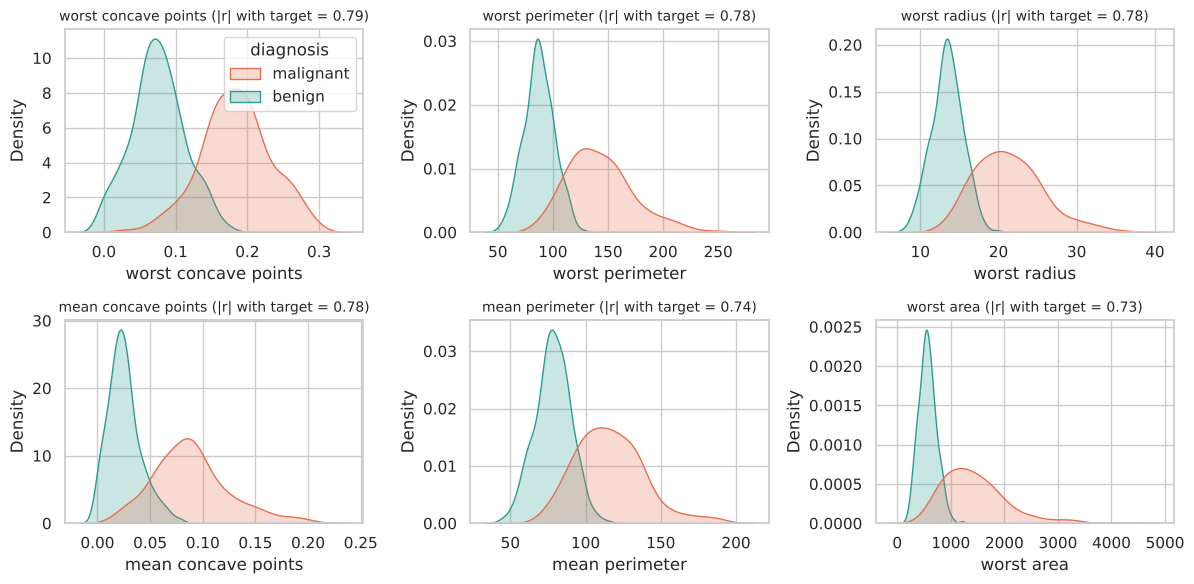

In [5]:
corr_y = X_train.corrwith(y_train).abs().sort_values(ascending=False)
top6 = corr_y.index[:6].tolist()
plot_df = X_train[top6].assign(diagnosis=y_train.map({0: "benign", 1: "malignant"}))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, feat in zip(axes.ravel(), top6):
    sns.kdeplot(data=plot_df, x=feat, hue="diagnosis", fill=True, common_norm=False,
                palette={"benign": "#2a9d8f", "malignant": "#e76f51"}, ax=ax, legend=(feat == top6[0]))
    ax.set_title(f"{feat} (|r| with target = {corr_y[feat]:.2f})", fontsize=10)
savefig("eda2_top_feature_distributions")

**EDA 3: feature correlation.**

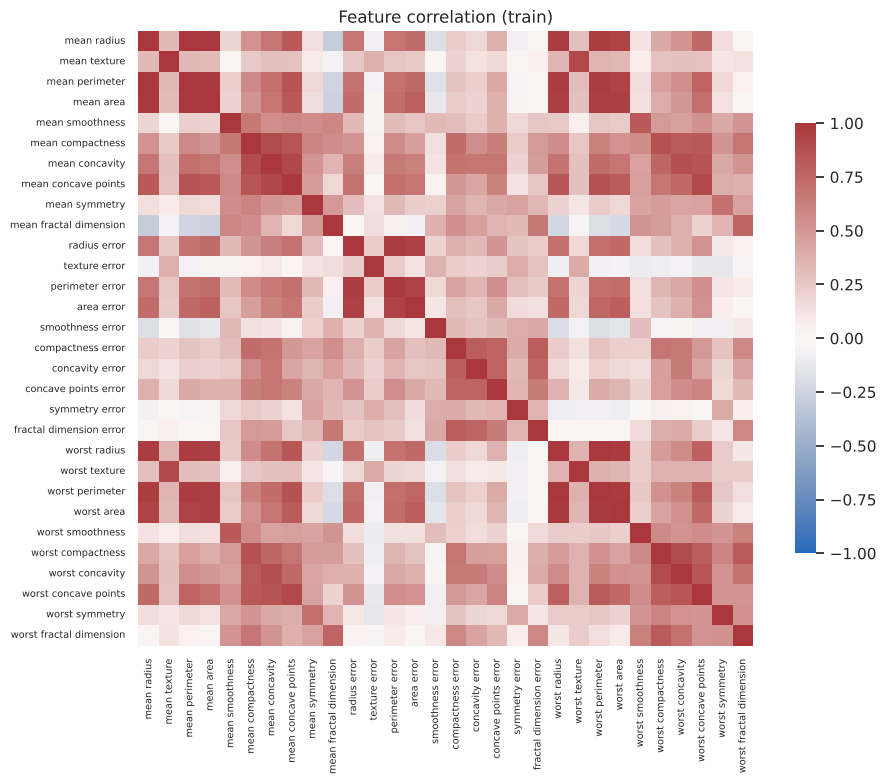

feature pairs with |r| > 0.9: 21 of 435
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.986
worst radius    worst area         0.983


In [6]:
C = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(C, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.tick_params(labelsize=7); ax.set_title("Feature correlation (train)")
savefig("eda3_correlation_heatmap")

upper = C.where(np.triu(np.ones(C.shape, dtype=bool), k=1))
pairs = upper.stack().dropna()
print("feature pairs with |r| > 0.9:", int((pairs.abs() > 0.9).sum()), "of", len(pairs))
print(pairs.abs().sort_values(ascending=False).head(5).round(3).to_string())

**EDA 4: outliers (IQR rule).**

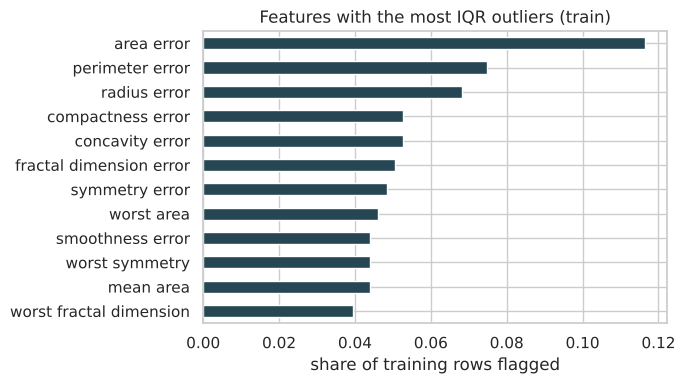

features with >5% flagged rows: 6 of 30


In [7]:
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
out_frac = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
out_frac.head(12)[::-1].plot.barh(ax=ax, color="#264653")
ax.set_xlabel("share of training rows flagged"); ax.set_title("Features with the most IQR outliers (train)")
savefig("eda4_outliers")
print("features with >5% flagged rows:", int((out_frac > 0.05).sum()), "of", X_train.shape[1])

**EDA interpretation**


- **Class balance.** The training split is 62.6% benign and 37.4% malignant. That is a mild imbalance, so accuracy alone would be slightly flattering; the majority-class rate is about 0.63.
- **Separability.** The most class-informative single features are size and shape measures: worst concave points, worst perimeter, worst radius, mean concave points (|r| with the target about 0.78 to 0.79). The class densities overlap only partly, which is why even a stump-based model can score well, and why the hard cases sit in the overlap region.
- **Correlation.** 21 of 435 feature pairs have |r| > 0.9, mostly radius, perimeter and area of the same measurement (for example mean radius and mean perimeter, r = 0.998). Trees tolerate this, but it means feature importances will be spread across near-duplicate features.
- **Scales and outliers.** Feature means range from about 0.004 to about 890, which would matter for distance-based or linear models but not for trees (hence no scaling). Six of 30 features have more than 5% of rows flagged by the IQR rule, mainly the "error" (standard error) features such as area error (11.6%). These are skewed measurements, not data errors, so they are kept.

## 5. Preprocessing and split strategy

| Step | Decision | Reason |
|---|---|---|
| Missing values | None to handle | 0 missing values (checked above) |
| Encoding | None | All 30 features are numeric; the target is binary |
| Scaling | **Not used** | Trees split on thresholds, so a monotonic rescaling of a feature does not change the model. Because no transformer is fitted, nothing can leak from the test set into preprocessing. |
| Imbalance handling | **Not used** | About 37% malignant is a mild imbalance. Stratified splitting keeps the share constant everywhere, and we report recall, F1 and ROC-AUC besides accuracy. |
| Outliers | Kept | Tree models are robust to them, and large values are real tumour measurements |
| Correlated features | Kept | Trees tolerate them. They do split importance credit among correlated features, which is discussed in section 10. |

**Splits**
- One stratified 80/20 train/test split (seed 42). The test set is used **once**, for the final evaluation in section 7.
- All model comparison and tuning-style decisions use **cross-validation inside the training set**. The main comparison uses 5-fold x 3 repeats stratified CV (15 folds). The sweeps use 5-fold stratified CV. The same CV objects (same seeds) are reused for every model, so all models see identical folds.
- No hyperparameter in the main comparison was tuned on the test set. The configurations are fixed up front (below).

In [8]:
cv_main = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# sanity check: identical folds on every call
a = [tuple(te) for _, te in cv_main.split(X_train, y_train)]
b = [tuple(te) for _, te in cv_main.split(X_train, y_train)]
assert a == b
print("CV folds reproducible; main CV has", len(a), "folds")

CV folds reproducible; main CV has 15 folds


## 6. Baseline and proposed methods

| Model | Role | Configuration |
|---|---|---|
| Decision Tree | baseline | scikit-learn defaults (unpruned, Gini) |
| Random Forest | bagging | 200 trees, unpruned trees, `max_features="sqrt"` (default), bootstrap on |
| AdaBoost | boosting | 200 stumps (depth-1 trees), learning rate 1.0 |
| Gradient Boosting | boosting | 200 trees, depth 3, learning rate 0.1, deviance (log) loss |

All use `random_state=42` and a single CPU thread (`n_jobs=1`) so that timings are comparable. The configurations are common textbook defaults, chosen before looking at any results, not tuned to this dataset. Sections 8 and 9 show how sensitive they are.

In [9]:
def make_models():
    return {
        "Decision Tree":     DecisionTreeClassifier(random_state=SEED),
        "Random Forest":     RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
        "AdaBoost":          AdaBoostClassifier(n_estimators=200, learning_rate=1.0, random_state=SEED),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                        max_depth=3, random_state=SEED),
    }
MODEL_NAMES = list(make_models())
for n, m in make_models().items():
    print(f"{n:18s}", m)

Decision Tree      DecisionTreeClassifier(random_state=42)
Random Forest      RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=42)
AdaBoost           AdaBoostClassifier(n_estimators=200, random_state=42)
Gradient Boosting  GradientBoostingClassifier(n_estimators=200, random_state=42)


## 7. Experiment 1: main comparison

**7a. Repeated stratified CV on the training set** (5 folds x 3 repeats). Reports mean and standard deviation across the 15 folds, plus training-fold accuracy to expose overfitting.

In [10]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
frames = []
for name, model in make_models().items():
    res = cross_validate(model, X_train, y_train, cv=cv_main, scoring=scoring,
                         return_train_score=True, n_jobs=1)
    df = pd.DataFrame(res)
    df["model"] = name
    df["fold"] = np.arange(len(df))
    frames.append(df)
cv_raw = pd.concat(frames, ignore_index=True)
cv_raw.to_csv("results/exp1_cv_fold_scores.csv", index=False)

metric_cols = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc",
               "train_accuracy", "fit_time"]
cv_mean = cv_raw.groupby("model")[metric_cols].mean().loc[MODEL_NAMES]
cv_std = cv_raw.groupby("model")[metric_cols].std().loc[MODEL_NAMES]
cv_table = cv_mean.round(4).astype(str) + " ± " + cv_std.round(4).astype(str)
cv_table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Train acc", "Fit time (s)"]
cv_table.to_csv("results/exp1_cv_summary.csv")
cv_table

,Accuracy,Precision,Recall,F1,ROC-AUC,Train acc,Fit time (s)
model,,,,,,,
Decision Tree,0.9216 ± 0.0313,0.897 ± 0.0465,0.8941 ± 0.0519,0.8949 ± 0.042,0.9161 ± 0.0342,1.0 ± 0.0,0.0059 ± 0.0007
Random Forest,0.9568 ± 0.024,0.9572 ± 0.0388,0.9275 ± 0.0532,0.9409 ± 0.0333,0.9898 ± 0.0082,1.0 ± 0.0,0.2804 ± 0.0224
AdaBoost,0.9736 ± 0.016,0.9859 ± 0.019,0.9431 ± 0.036,0.9637 ± 0.0225,0.9949 ± 0.0051,1.0 ± 0.0,0.4577 ± 0.0335
Gradient Boosting,0.959 ± 0.0277,0.9598 ± 0.0323,0.9294 ± 0.0586,0.9436 ± 0.0391,0.991 ± 0.0084,1.0 ± 0.0,0.5455 ± 0.0382


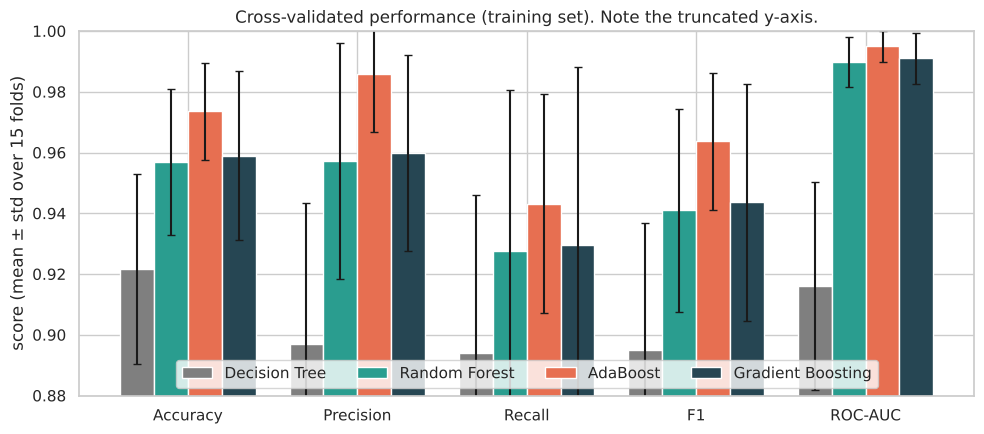

In [11]:
metrics = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
labels = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.2
for i, name in enumerate(MODEL_NAMES):
    ax.bar(np.arange(len(metrics)) + (i - 1.5) * w, cv_mean.loc[name, metrics], w,
           yerr=cv_std.loc[name, metrics], capsize=3, label=name, color=COLORS[name])
ax.set_xticks(np.arange(len(metrics))); ax.set_xticklabels(labels)
ax.set_ylim(0.88, 1.0); ax.set_ylabel("score (mean ± std over 15 folds)")
ax.set_title("Cross-validated performance (training set). Note the truncated y-axis.")
ax.legend(ncol=4, loc="lower center")
savefig("exp1_cv_metric_comparison")

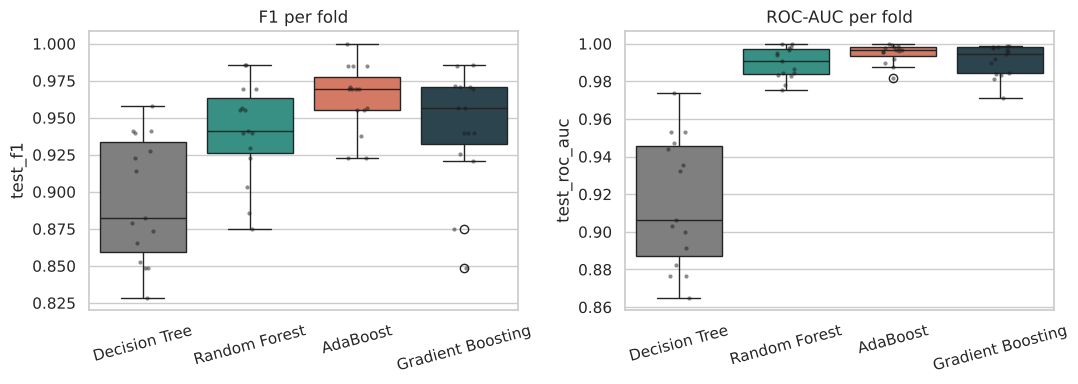

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["test_f1", "test_roc_auc"], ["F1 per fold", "ROC-AUC per fold"]):
    sns.boxplot(data=cv_raw, x="model", y=metric, order=MODEL_NAMES, palette=COLORS,
                hue="model", legend=False, ax=ax)
    sns.stripplot(data=cv_raw, x="model", y=metric, order=MODEL_NAMES, color="k", size=3, alpha=0.5, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
savefig("exp1_cv_fold_spread")

**7b. Final evaluation on the held-out test set.** Each model is fit on the full training set and evaluated once on the test set. Training time is the median of 5 refits, inference time is the median of 30 predictions of the whole test set, and size is the pickled model. The F1 confidence interval is a 95% percentile bootstrap over test samples (1000 resamples, seeded). It shows how coarse a 114-sample test set is.

In [13]:
def n_nodes(m):
    if hasattr(m, "tree_"):
        return m.tree_.node_count
    ests = np.ravel(m.estimators_)
    return int(sum(e.tree_.node_count for e in ests))

def bootstrap_f1_ci(y_true, y_pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(yt), len(yt))
        vals.append(f1_score(yt[idx], yp[idx], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])

fitted, rows = {}, []
for name, model in make_models().items():
    fit_times = []
    for _ in range(5):
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_train, y_train); fit_times.append(time.perf_counter() - t0)
    fitted[name] = m
    pred_times = []
    for _ in range(30):
        t0 = time.perf_counter(); m.predict(X_test); pred_times.append(time.perf_counter() - t0)
    y_pred = m.predict(X_test)
    y_prob = m.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    lo, hi = bootstrap_f1_ci(y_test, y_pred)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "f1_ci_low": lo, "f1_ci_high": hi,
        "roc_auc": roc_auc_score(y_test, y_prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "train_time_s": float(np.median(fit_times)),
        "predict_time_ms": 1000 * float(np.median(pred_times)),
        "size_KB": len(pickle.dumps(m)) / 1024,
        "total_tree_nodes": n_nodes(m),
    })
test_df = pd.DataFrame(rows).set_index("model")
test_df.round(4).to_csv("results/exp1_test_results.csv")
test_df.round(4)

,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,roc_auc,TN,FP,FN,TP,train_time_s,predict_time_ms,size_KB,total_tree_nodes
model,,,,,,,,,,,,,,,
Decision Tree,0.9298,0.9048,0.9048,0.9048,0.8267,0.9630,0.9246,68,4,4,38,0.0079,0.6192,5.4043,47
Random Forest,0.9649,1.0000,0.9048,0.9500,0.8974,0.9903,0.9942,72,0,4,38,0.3025,13.6857,626.5586,7234
AdaBoost,0.9737,1.0000,0.9286,0.9630,0.9118,1.0000,0.9871,72,0,3,39,0.5098,24.8612,110.0244,600
Gradient Boosting,0.9649,1.0000,0.9048,0.9500,0.8928,1.0000,0.9954,72,0,4,38,0.6537,1.1330,257.1602,2880


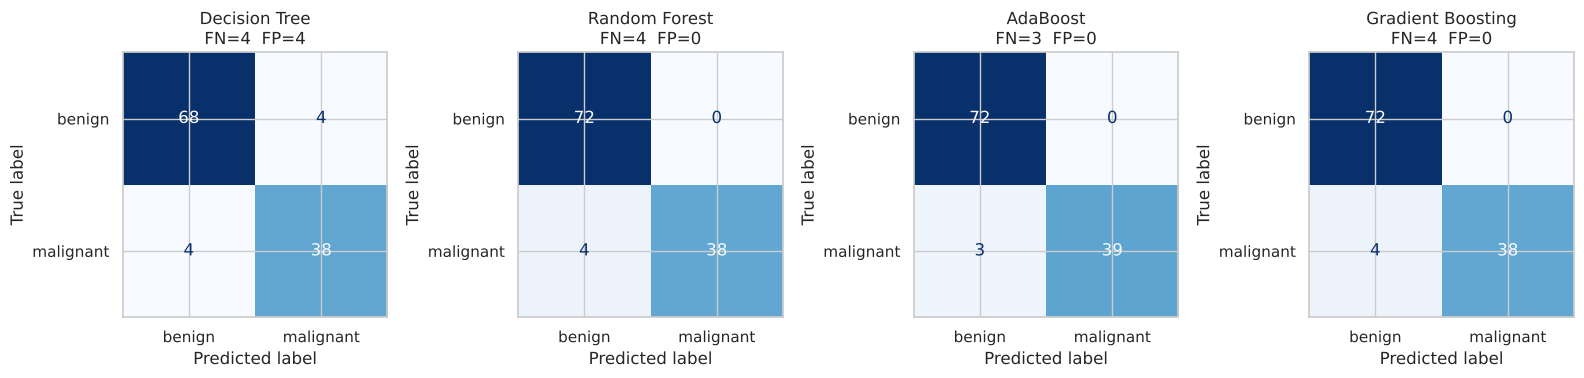

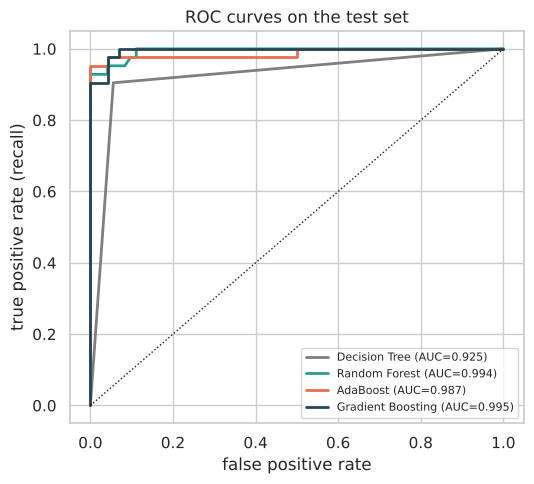

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, name in zip(axes, MODEL_NAMES):
    cm = confusion_matrix(y_test, fitted[name].predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nFN={cm[1,0]}  FP={cm[0,1]}")
savefig("exp1_test_confusion_matrices")

fig, ax = plt.subplots(figsize=(5.5, 5))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, fitted[name].predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, label=f"{name} (AUC={test_df.loc[name, 'roc_auc']:.3f})", color=COLORS[name], lw=2)
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate (recall)")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right", fontsize=8)
savefig("exp1_test_roc_curves")

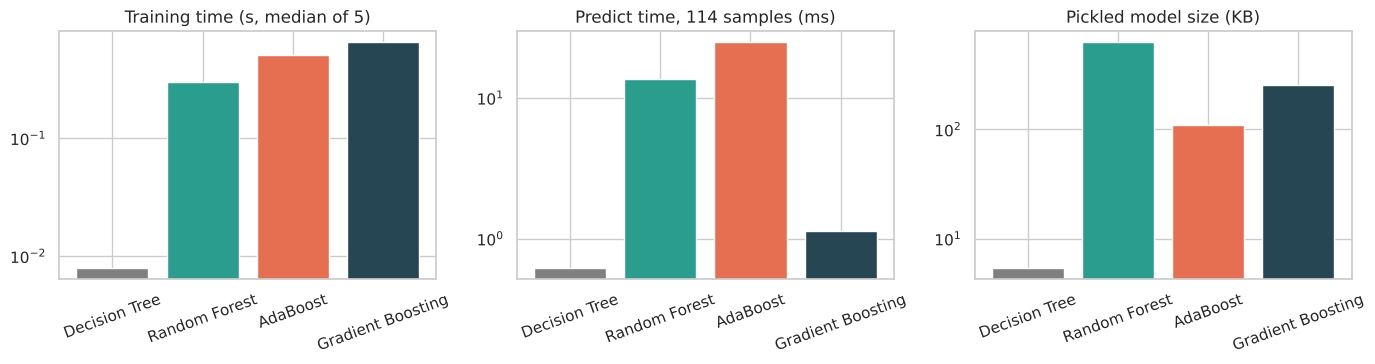

,train_time_s,predict_time_ms,size_KB,total_tree_nodes
model,,,,
Decision Tree,0.008,0.619,5.404,47
Random Forest,0.302,13.686,626.559,7234
AdaBoost,0.510,24.861,110.024,600
Gradient Boosting,0.654,1.133,257.160,2880


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes, ["train_time_s", "predict_time_ms", "size_KB"],
                          ["Training time (s, median of 5)", "Predict time, 114 samples (ms)", "Pickled model size (KB)"]):
    ax.bar(MODEL_NAMES, test_df.loc[MODEL_NAMES, col], color=[COLORS[n] for n in MODEL_NAMES])
    ax.set_title(title); ax.set_yscale("log"); ax.tick_params(axis="x", rotation=20)
savefig("exp1_cost_comparison")
test_df[["train_time_s", "predict_time_ms", "size_KB", "total_tree_nodes"]].round(3)

**Experiment 1 analysis**


**Cross-validation (15 folds, training set).** All three ensembles clearly beat the single tree. Mean F1: Decision Tree 0.895, Random Forest 0.941, Gradient Boosting 0.944, AdaBoost 0.964. ROC-AUC shows a bigger gap: 0.916 for the tree against 0.990 to 0.995 for the ensembles. A single tree gives only hard 0/1 leaf probabilities, so its ranking quality is poor even when its accuracy is acceptable. All four models reach training accuracy 1.0, so the real difference is in generalization, not in fit.

The ensembles beat the tree in all 15 folds on both F1 and ROC-AUC (section 10c). Among the ensembles the differences are small relative to the fold-to-fold spread (std about 0.02 to 0.04). AdaBoost has the best mean F1 and ROC-AUC, but the lead over Random Forest and Gradient Boosting is about 2 F1 points, and after Bonferroni correction only the AdaBoost vs Random Forest F1 comparison stays just under 0.05 (p = 0.047). Random Forest and Gradient Boosting are statistically indistinguishable here (F1 difference 0.003).

**Held-out test set (114 samples).** Errors: Decision Tree 8, Random Forest 4, Gradient Boosting 4, AdaBoost 3. This agrees with the CV ranking, but the F1 bootstrap intervals overlap heavily (tree 0.83 to 0.96, AdaBoost 0.91 to 1.00), so the test set alone cannot separate the ensembles. Treat the CV numbers as the main evidence and the test set as a confirmation that nothing was overfit to the CV.

**Precision/recall pattern.** All three ensembles have zero false positives on the test set but still miss 3 to 4 malignant cases (recall 0.90 to 0.93). At the default 0.5 threshold they lean toward precision. For a screening use case the threshold would be lowered to trade false alarms for recall; that is outside this project's scope (it is the topic of Project 7), but it is the most important practical change.

**Cost.** In absolute terms everything is cheap (under 1 s to train, under 25 ms to predict 114 samples). Relative to the tree, training is roughly 40x (RF), 65x (AdaBoost) and 85x (Gradient Boosting) slower (timings vary a few percent between runs), and the models are much larger: 5 KB for the tree, 626 KB for Random Forest (7,234 nodes), 257 KB for Gradient Boosting and 110 KB for AdaBoost (600 nodes). Random Forest is large because its trees are unpruned. Prediction time does not follow model size: Gradient Boosting predicted fastest among the ensembles (about 1.3 ms) despite 2,880 nodes, while AdaBoost was slowest (about 24 ms). That is an implementation effect in scikit-learn, not a property of the algorithms, so it should not be generalized.

## 8. Experiment 2: number of estimators

Controlled variable: `n_estimators` in {1, 5, 10, 25, 50, 100, 200, 300}. Everything else is fixed: RF with unpruned trees; AdaBoost with stumps and learning rate 1.0; Gradient Boosting with depth 3 and learning rate 0.1. Evaluated with the same 5-fold stratified CV on the training set. The dashed line is a single decision tree under the same CV.

In [16]:
n_list = [1, 5, 10, 25, 50, 100, 200, 300]
factories_n = {
    "Random Forest":     lambda n: RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=1),
    "AdaBoost":          lambda n: AdaBoostClassifier(n_estimators=n, random_state=SEED),
    "Gradient Boosting": lambda n: GradientBoostingClassifier(n_estimators=n, max_depth=3,
                                                              learning_rate=0.1, random_state=SEED),
}
sc = {"f1": "f1", "roc_auc": "roc_auc", "accuracy": "accuracy"}
rows = []
for name, mk in factories_n.items():
    for n in n_list:
        r = cross_validate(mk(n), X_train, y_train, cv=cv5, scoring=sc, return_train_score=True, n_jobs=1)
        for k in range(5):
            rows.append({"model": name, "n_estimators": n, "fold": k, "f1": r["test_f1"][k],
                         "roc_auc": r["test_roc_auc"][k], "accuracy": r["test_accuracy"][k],
                         "train_accuracy": r["train_accuracy"][k], "fit_time": r["fit_time"][k]})
sweep_n = pd.DataFrame(rows)
sweep_n.to_csv("results/exp2_n_estimators_fold_scores.csv", index=False)

dt_ref = cross_validate(DecisionTreeClassifier(random_state=SEED), X_train, y_train, cv=cv5,
                        scoring=sc, n_jobs=1)
dt_f1, dt_auc = dt_ref["test_f1"].mean(), dt_ref["test_roc_auc"].mean()

agg_n = sweep_n.groupby(["model", "n_estimators"]).agg(
    f1=("f1", "mean"), f1_std=("f1", "std"), roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"),
    accuracy=("accuracy", "mean"), fit_time=("fit_time", "mean")).reset_index()
agg_n.round(4).to_csv("results/exp2_n_estimators_summary.csv", index=False)
print(f"Decision Tree reference (5-fold CV): F1={dt_f1:.4f}, ROC-AUC={dt_auc:.4f}")
agg_n.pivot(index="n_estimators", columns="model", values="f1").round(4)

Decision Tree reference (5-fold CV): F1=0.8962, ROC-AUC=0.9172


model,AdaBoost,Gradient Boosting,Random Forest
n_estimators,,,
1,0.8562,0.0000,0.8830
5,0.9180,0.9112,0.9344
10,0.9256,0.9233,0.9302
25,0.9488,0.9275,0.9492
50,0.9546,0.9404,0.9464
100,0.9523,0.9553,0.9519
200,0.9610,0.9582,0.9489
300,0.9671,0.9549,0.9461


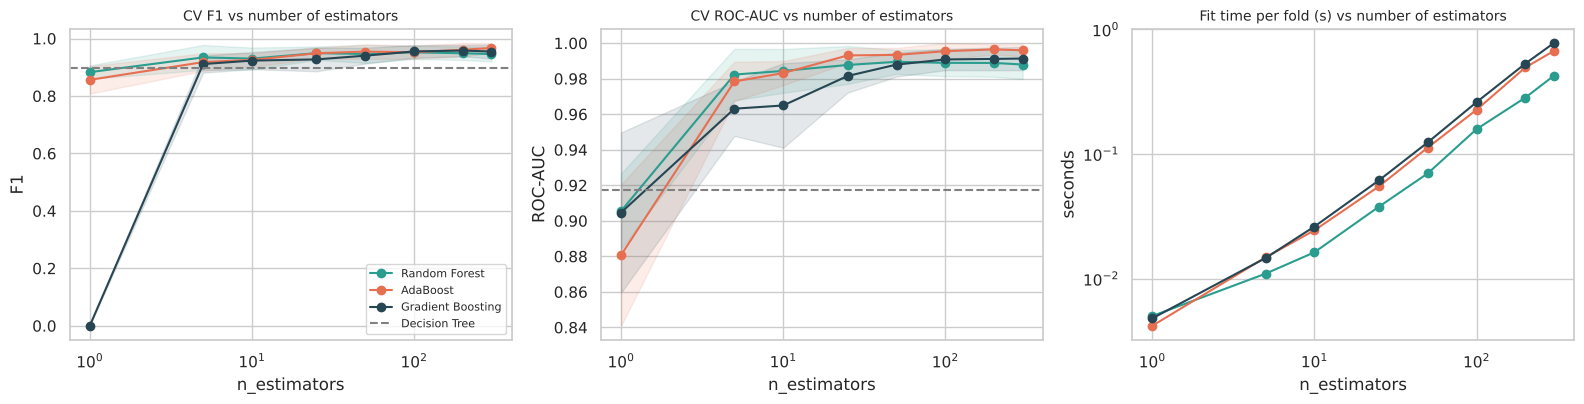

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name in factories_n:
    d = agg_n[agg_n.model == name]
    for ax, col, sd in [(axes[0], "f1", "f1_std"), (axes[1], "roc_auc", "roc_auc_std")]:
        ax.plot(d.n_estimators, d[col], marker="o", label=name, color=COLORS[name])
        ax.fill_between(d.n_estimators, d[col] - d[sd], d[col] + d[sd], color=COLORS[name], alpha=0.12)
    axes[2].plot(d.n_estimators, d.fit_time, marker="o", label=name, color=COLORS[name])
axes[0].axhline(dt_f1, color="gray", ls="--", label="Decision Tree")
axes[1].axhline(dt_auc, color="gray", ls="--", label="Decision Tree")
for ax, t in zip(axes, ["CV F1 vs number of estimators", "CV ROC-AUC vs number of estimators",
                        "Fit time per fold (s) vs number of estimators"]):
    ax.set_xscale("log"); ax.set_xlabel("n_estimators"); ax.set_title(t, fontsize=10)
axes[0].set_ylabel("F1"); axes[1].set_ylabel("ROC-AUC"); axes[2].set_ylabel("seconds"); axes[2].set_yscale("log")
axes[0].legend(fontsize=8)
savefig("exp2_n_estimators")

**Experiment 2 analysis**


- **Bagging plateaus early.** Random Forest CV F1 is about 0.949 at 25 trees and stays between 0.946 and 0.952 up to 300 trees. More trees do not hurt (averaging more trees cannot increase variance), but they stop helping after a few dozen, while the fit time keeps growing roughly linearly (0.04 s at 25 trees, 0.44 s at 300).
- **Boosting keeps improving longer.** AdaBoost rises from 0.949 (25) to 0.961 (200) and 0.967 (300), and its ROC-AUC peaks at 200 (0.9965). Gradient Boosting rises to about 0.958 at 200 and is flat after that (0.955 at 300). Neither shows a clear degradation by 300 estimators on this dataset, although the curves are noisy at the 0.005 level, so we do not claim a specific optimum.
- **One estimator.** A single AdaBoost stump (F1 0.856) and a single forest tree (0.883) work as weak models. Gradient Boosting with one tree has F1 = 0 because the learning rate of 0.1 makes one tree's contribution too small to push any predicted probability above 0.5 (verified: no training sample is predicted malignant, maximum probability 0.44). This is an artifact of the shrinkage setting, not a failure of the method.
- **Cost vs gain.** Going from 100 to 300 estimators roughly triples the fit time for all three methods and buys at most about 0.015 F1 (AdaBoost) and nothing for Random Forest. For this dataset, 50 to 100 estimators is a sensible stopping point for bagging and 100 to 200 for boosting.
- From 5 estimators on, all three ensembles are above the single-tree reference (CV F1 about 0.896 under the same CV); with a single estimator they are all below it.

## 9. Experiment 3: tree depth

Controlled variable: `max_depth` of the trees in {1, 2, 3, 4, 6, 8, unlimited}. For AdaBoost the depth is that of the weak learner. 100 estimators for the ensembles, learning rate 0.1 for Gradient Boosting, 1.0 for AdaBoost. 5-fold CV on the training set; train and validation F1 are plotted to show the generalization gap. The unlimited-depth setting is skipped for AdaBoost: an unlimited tree fits the weighted training set perfectly in the first round, after which AdaBoost has nothing left to re-weight.

In [18]:
depths = [1, 2, 3, 4, 6, 8, None]
dlabels = [str(d) if d is not None else "None" for d in depths]
factories_d = {
    "Decision Tree":     lambda d: DecisionTreeClassifier(max_depth=d, random_state=SEED),
    "Random Forest":     lambda d: RandomForestClassifier(n_estimators=100, max_depth=d, random_state=SEED, n_jobs=1),
    "AdaBoost":          lambda d: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=d, random_state=SEED),
                                                      n_estimators=100, random_state=SEED),
    "Gradient Boosting": lambda d: GradientBoostingClassifier(n_estimators=100, max_depth=d,
                                                              learning_rate=0.1, random_state=SEED),
}
rows = []
for name, mk in factories_d.items():
    for d, dl in zip(depths, dlabels):
        if name == "AdaBoost" and d is None:
            continue
        r = cross_validate(mk(d), X_train, y_train, cv=cv5, scoring={"f1": "f1", "roc_auc": "roc_auc"},
                           return_train_score=True, n_jobs=1)
        rows.append({"model": name, "max_depth": dl, "train_f1": r["train_f1"].mean(),
                     "cv_f1": r["test_f1"].mean(), "cv_f1_std": r["test_f1"].std(),
                     "cv_roc_auc": r["test_roc_auc"].mean(), "fit_time": r["fit_time"].mean()})
sweep_d = pd.DataFrame(rows)
sweep_d["gap"] = sweep_d.train_f1 - sweep_d.cv_f1
sweep_d.round(4).to_csv("results/exp3_depth_summary.csv", index=False)
sweep_d.pivot(index="max_depth", columns="model", values="cv_f1").loc[dlabels].round(4)

model,AdaBoost,Decision Tree,Gradient Boosting,Random Forest
max_depth,,,,
1,0.9523,0.8562,0.9514,0.8935
2,0.9610,0.8892,0.9551,0.9256
3,0.9643,0.8884,0.9553,0.9401
4,0.9525,0.8897,0.9439,0.9430
6,0.9230,0.8919,0.8970,0.9550
8,0.8958,0.8962,0.8980,0.9519
None,NaN,0.8962,0.9035,0.9519


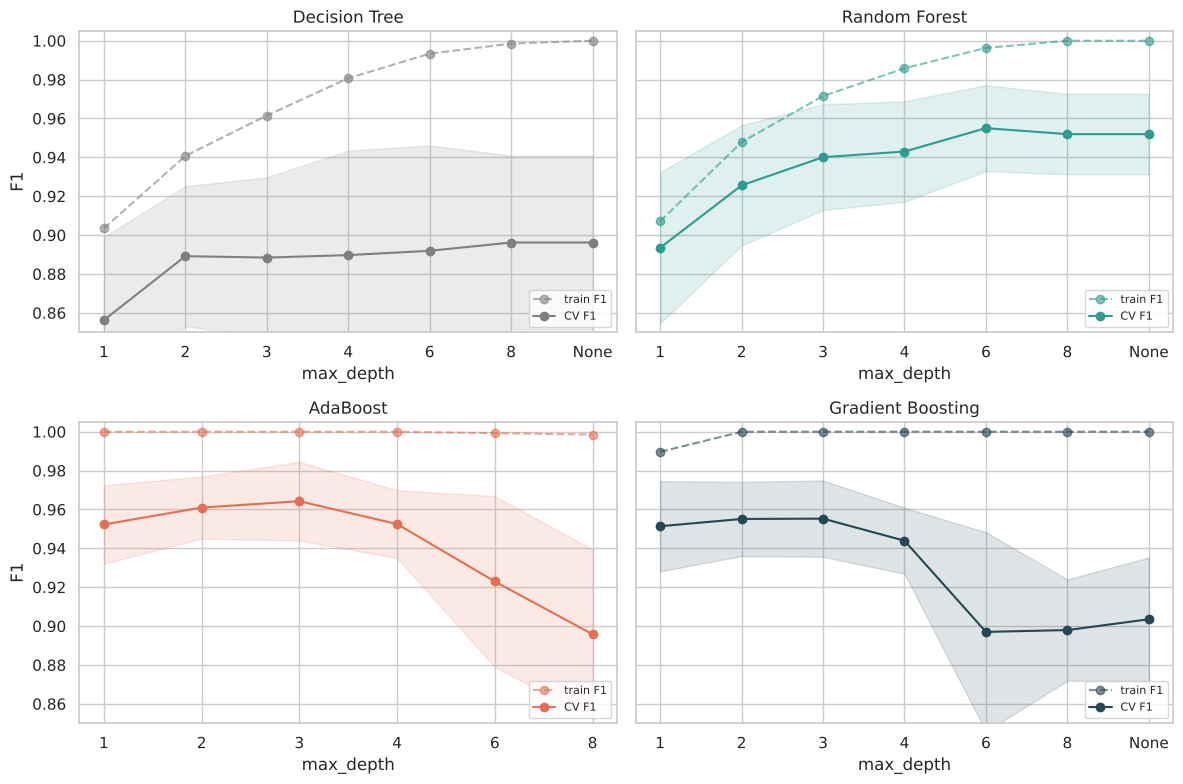

,model,max_depth,cv_f1,cv_roc_auc,gap
16,AdaBoost,3,0.9643,0.9948,0.0357
5,Decision Tree,8,0.8962,0.9172,0.1023
22,Gradient Boosting,3,0.9553,0.9908,0.0447
11,Random Forest,6,0.9550,0.9888,0.0413


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, name in zip(axes.ravel(), factories_d):
    d = sweep_d[sweep_d.model == name].set_index("max_depth").reindex([l for l in dlabels
                                                                       if l in set(sweep_d[sweep_d.model == name].max_depth)])
    x = np.arange(len(d))
    ax.plot(x, d.train_f1, "o--", color=COLORS[name], alpha=0.6, label="train F1")
    ax.plot(x, d.cv_f1, "o-", color=COLORS[name], label="CV F1")
    ax.fill_between(x, d.cv_f1 - d.cv_f1_std, d.cv_f1 + d.cv_f1_std, color=COLORS[name], alpha=0.15)
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_xlabel("max_depth"); ax.set_title(name)
    ax.set_ylim(0.85, 1.005); ax.legend(loc="lower right", fontsize=8)
axes[0, 0].set_ylabel("F1"); axes[1, 0].set_ylabel("F1")
savefig("exp3_depth_train_vs_cv")

best = sweep_d.loc[sweep_d.groupby("model").cv_f1.idxmax(), ["model", "max_depth", "cv_f1", "cv_roc_auc", "gap"]]
best.round(4)

**Experiment 3 analysis**


- **Single tree.** Training F1 rises to 1.0 with depth, while CV F1 stays around 0.89 for every depth from 2 up. The gap grows from 0.05 to 0.10. Deeper trees memorize the training data without generalizing better; this is the high-variance behaviour that bagging is designed to fix.
- **Random Forest** improves with depth up to about 6 (CV F1 0.894 at depth 1, 0.943 at depth 4, 0.955 at depth 6) and is flat after that (0.952 for 8 and unlimited). Its training F1 reaches 1.0 at depth 8, yet validation F1 does not fall. Unpruned trees are fine inside a bagged ensemble, because averaging removes much of the variance of the individual trees. The generalization gap (about 0.05) is not a problem here since validation performance does not drop.
- **AdaBoost** works best with very shallow learners: CV F1 0.952 for stumps, 0.961 for depth 2 and 0.964 for depth 3, falling to 0.953 at depth 4, 0.923 at depth 6 and 0.896 at depth 8. We checked the cause: with depth 6 only 9 of the 100 rounds were run, and with depth 8 only 1, because the deep tree fits the training data perfectly and boosting stops. Deep base learners therefore turn AdaBoost back into roughly a single tree, and the CV F1 at depth 8 (0.896) matches the single tree (0.896).
- **Gradient Boosting** is best at depth 2 to 3 (about 0.955) and degrades from depth 4 (0.944), clearly at depth 6 and above (about 0.90). Its training loss at depth 6 falls to about 5e-5 after 100 rounds against 4e-3 for depth 3, so the deeper trees fit the training data much faster and generalize worse. This is consistent with overfitting; we did not test the mechanism further.
- **Takeaway.** Bagging and boosting want opposite base learners. Bagging wants low-bias, high-variance trees (deep, unpruned) and averages the variance away. Boosting wants weak, high-bias learners (depth 1 to 3) and reduces the bias step by step. Given deep trees, boosting overfits or stops early; given stumps, a forest underperforms (RF depth 1 gives CV F1 0.894, versus 0.952 for AdaBoost stumps).

## 10. Interpretability, failure cases and a statistical check

**10a. Interpretability.** A single tree can be read as a handful of rules. An ensemble of hundreds of trees cannot, so we only get aggregate feature importances (impurity-based here). Impurity importances are biased toward high-cardinality features, and with strongly correlated features the credit is split between them arbitrarily, so they show what the model used, not what causes malignancy.

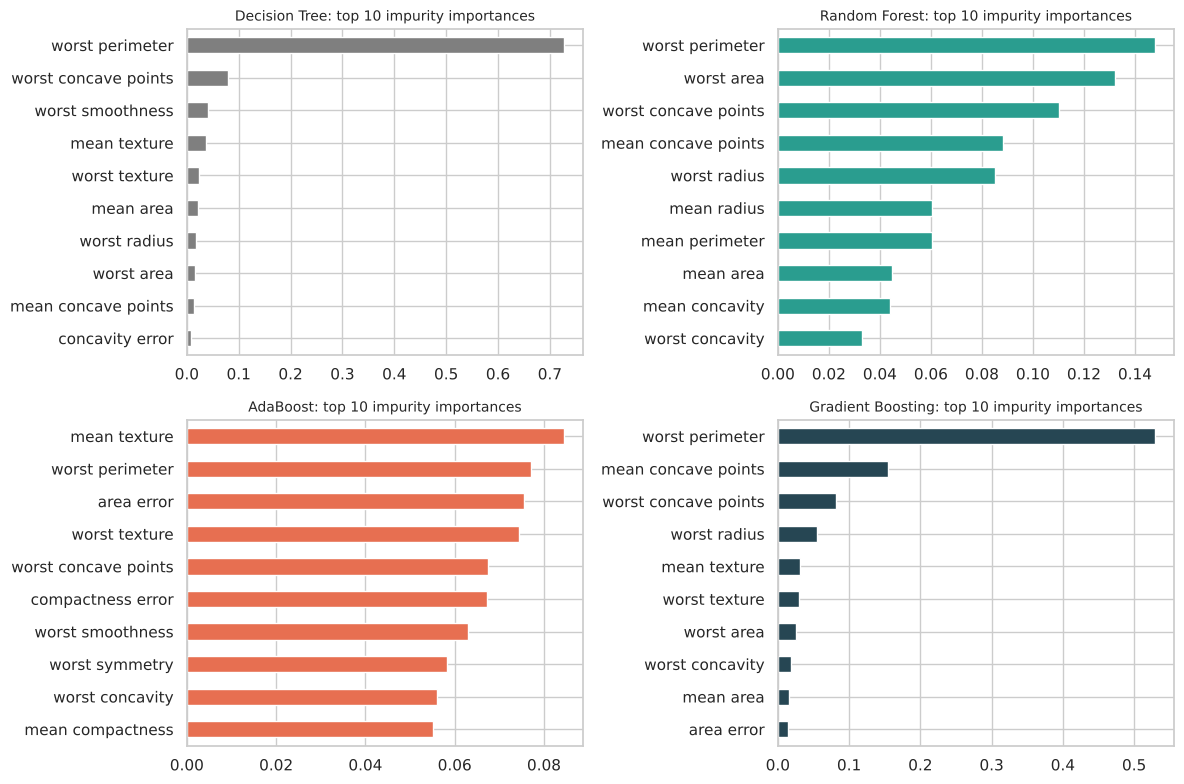

Spearman rank correlation of importances between models:
                   Decision Tree  Random Forest  AdaBoost  Gradient Boosting
Decision Tree               1.00           0.68      0.37               0.71
Random Forest               0.68           1.00      0.21               0.59
AdaBoost                    0.37           0.21      1.00               0.53
Gradient Boosting           0.71           0.59      0.53               1.00

Decision Tree      top-5: ['worst perimeter', 'worst concave points', 'worst smoothness', 'mean texture', 'worst texture']
Random Forest      top-5: ['worst perimeter', 'worst area', 'worst concave points', 'mean concave points', 'worst radius']
AdaBoost           top-5: ['mean texture', 'worst perimeter', 'area error', 'worst texture', 'worst concave points']
Gradient Boosting  top-5: ['worst perimeter', 'mean concave points', 'worst concave points', 'worst radius', 'mean texture']


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
imp = {}
for ax, name in zip(axes.ravel(), MODEL_NAMES):
    s = pd.Series(fitted[name].feature_importances_, index=X.columns)
    imp[name] = s
    s.sort_values().tail(10).plot.barh(ax=ax, color=COLORS[name])
    ax.set_title(f"{name}: top 10 impurity importances", fontsize=10)
savefig("interp_feature_importances")

imp_df = pd.DataFrame(imp)
rho = imp_df.corr(method="spearman")
print("Spearman rank correlation of importances between models:")
print(rho.round(2).to_string())
print()
for n in MODEL_NAMES:
    print(f"{n:18s} top-5:", imp_df[n].sort_values(ascending=False).head(5).index.tolist())

Decision tree: depth = 8 | leaves = 24 | nodes = 47


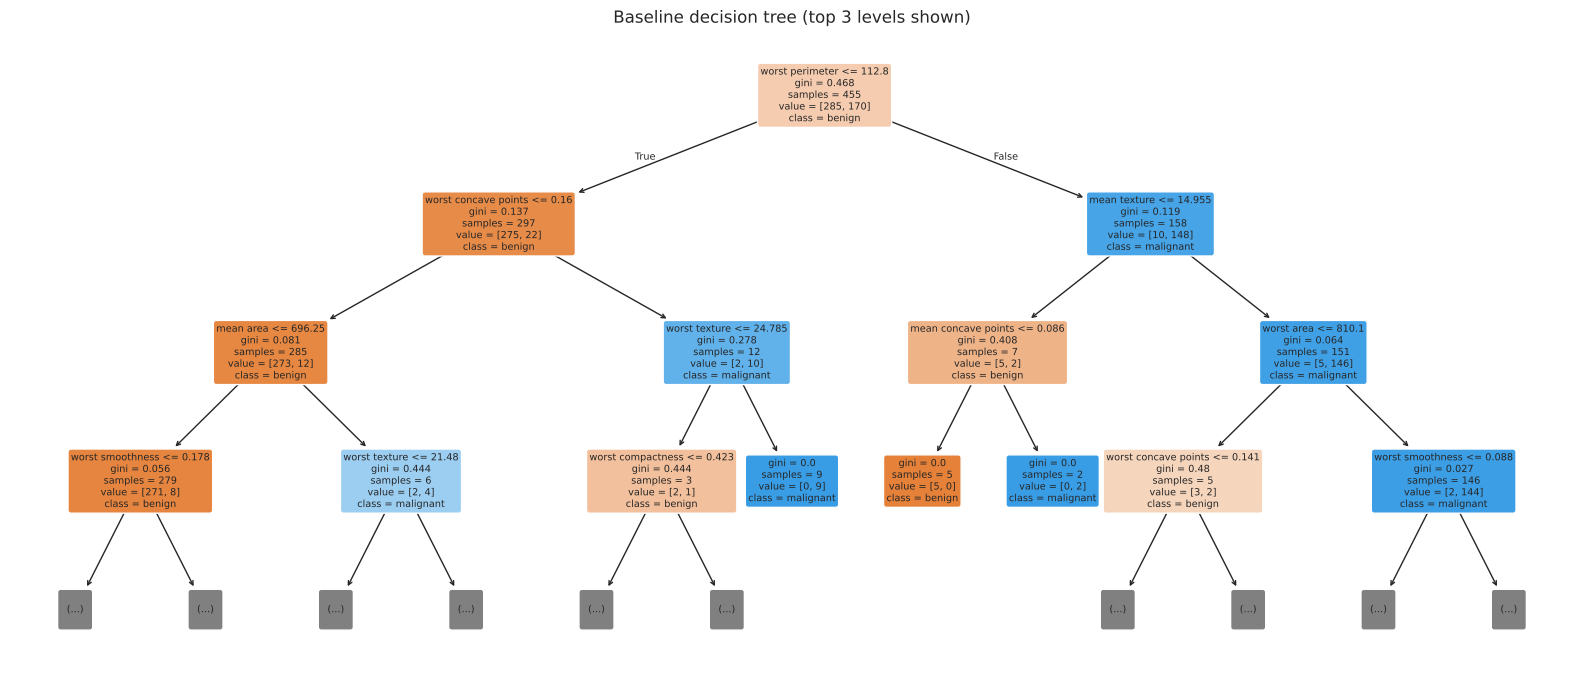

{'Decision Tree': 47, 'Random Forest': 7234, 'AdaBoost': 600, 'Gradient Boosting': 2880}


In [21]:
dt = fitted["Decision Tree"]
print("Decision tree: depth =", dt.get_depth(), "| leaves =", dt.get_n_leaves(), "| nodes =", dt.tree_.node_count)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(dt, max_depth=3, feature_names=X.columns.tolist(), class_names=["benign", "malignant"],
          filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title("Baseline decision tree (top 3 levels shown)")
savefig("interp_decision_tree_top_levels")
print({n: n_nodes(fitted[n]) for n in MODEL_NAMES})

**10b. Failure cases on the test set.** Which samples does each model get wrong, and are some samples hard for every model?

In [22]:
preds = {n: fitted[n].predict(X_test) for n in MODEL_NAMES}
wrong = {n: set(X_test.index[preds[n] != y_test.values]) for n in MODEL_NAMES}
for n in MODEL_NAMES:
    fn_ids = [i for i in wrong[n] if y_test.loc[i] == 1]
    fp_ids = [i for i in wrong[n] if y_test.loc[i] == 0]
    print(f"{n:18s} errors={len(wrong[n]):2d}  missed malignant (FN)={len(fn_ids)}  false alarms (FP)={len(fp_ids)}")

any_wrong = sorted(set().union(*wrong.values()))
all_wrong = sorted(set.intersection(*wrong.values()))
print("\nmisclassified by at least one model:", len(any_wrong))
print("misclassified by all four models   :", len(all_wrong), all_wrong)

tab = pd.DataFrame({"true": y_test.loc[any_wrong].map({0: "benign", 1: "malignant"})})
for n in MODEL_NAMES:
    tab[n] = pd.Series(preds[n], index=X_test.index).loc[any_wrong].map({0: "benign", 1: "malignant"})
tab["n_models_wrong"] = [sum(i in wrong[n] for n in MODEL_NAMES) for i in any_wrong]
tab.sort_values("n_models_wrong", ascending=False)

Decision Tree      errors= 8  missed malignant (FN)=4  false alarms (FP)=4
Random Forest      errors= 4  missed malignant (FN)=4  false alarms (FP)=0
AdaBoost           errors= 3  missed malignant (FN)=3  false alarms (FP)=0
Gradient Boosting  errors= 4  missed malignant (FN)=4  false alarms (FP)=0

misclassified by at least one model: 10
misclassified by all four models   : 1 [385]


,true,Decision Tree,Random Forest,AdaBoost,Gradient Boosting,n_models_wrong
385,malignant,benign,benign,benign,benign,4
73,malignant,malignant,benign,benign,benign,3
86,malignant,benign,benign,malignant,benign,3
205,malignant,malignant,malignant,benign,benign,2
100,malignant,benign,benign,malignant,malignant,2
5,malignant,benign,malignant,malignant,malignant,1
128,benign,malignant,benign,benign,benign,1
275,benign,malignant,benign,benign,benign,1
375,benign,malignant,benign,benign,benign,1
410,benign,malignant,benign,benign,benign,1


In [23]:
key = ["mean radius", "mean concave points", "worst perimeter", "worst concave points"]
if all_wrong:
    med = X_train.groupby(y_train)[key].median().rename(index={0: "median benign (train)", 1: "median malignant (train)"})
    hard = X_test.loc[all_wrong, key].copy()
    hard.index = [f"test sample {i} (true: {'malignant' if y_test.loc[i] else 'benign'})" for i in hard.index]
    display(pd.concat([hard, med]).round(3))
else:
    print("No sample is misclassified by all four models.")

,mean radius,mean concave points,worst perimeter,worst concave points
test sample 385 (true: malignant),14.600,0.053,102.20,0.136
median benign (train),12.210,0.023,87.00,0.074
median malignant (train),17.385,0.086,139.35,0.183


**10c. Paired statistical check on the CV folds.** The 15 CV folds are identical for every model, so fold scores can be compared pairwise (Wilcoxon signed-rank test on the per-fold differences). Caveat: folds from repeated CV share training data, so they are not independent and the p-values are optimistic. They are an indication, not a proof. Six pairs per metric are tested, so a Bonferroni-adjusted p-value (x6, capped at 1) is also shown.

In [24]:
pairs = [("Random Forest", "Decision Tree"), ("AdaBoost", "Decision Tree"), ("Gradient Boosting", "Decision Tree"),
         ("Random Forest", "AdaBoost"), ("Random Forest", "Gradient Boosting"), ("AdaBoost", "Gradient Boosting")]
rows = []
for metric in ["test_f1", "test_roc_auc"]:
    piv = cv_raw.pivot(index="fold", columns="model", values=metric)
    for a_, b_ in pairs:
        diff = piv[a_] - piv[b_]
        try:
            p = wilcoxon(diff).pvalue
        except ValueError:
            p = np.nan
        rows.append({"metric": metric.replace("test_", ""), "A": a_, "B": b_, "mean(A-B)": diff.mean(),
                     "A better in folds": int((diff > 0).sum()), "B better in folds": int((diff < 0).sum()),
                     "p": p, "p_bonferroni": min(1.0, p * len(pairs)) if p == p else np.nan})
stat_df = pd.DataFrame(rows)
stat_df.round(4).to_csv("results/exp1_paired_tests.csv", index=False)
stat_df.round(4)

,metric,A,B,mean(A-B),A better in folds,B better in folds,p,p_bonferroni
0,f1,Random Forest,Decision Tree,0.0461,15,0,0.0001,0.0004
1,f1,AdaBoost,Decision Tree,0.0688,15,0,0.0007,0.0039
2,f1,Gradient Boosting,Decision Tree,0.0487,15,0,0.0007,0.0039
3,f1,Random Forest,AdaBoost,-0.0228,3,10,0.0079,0.0474
4,f1,Random Forest,Gradient Boosting,-0.0026,3,7,0.5406,1.0000
5,f1,AdaBoost,Gradient Boosting,0.0201,8,3,0.0409,0.2452
6,roc_auc,Random Forest,Decision Tree,0.0738,15,0,0.0001,0.0004
7,roc_auc,AdaBoost,Decision Tree,0.0789,15,0,0.0001,0.0004
8,roc_auc,Gradient Boosting,Decision Tree,0.0749,15,0,0.0001,0.0004
9,roc_auc,Random Forest,AdaBoost,-0.0051,4,11,0.0287,0.1724


**Interpretability, failure-case and significance analysis**


**Interpretability.** The baseline tree has 47 nodes and 24 leaves (depth 8), and its top three levels can be read as threshold rules on worst perimeter, worst concave points and a few others. Even this unpruned tree is readable, a pruned depth-3 tree would be more so. The ensembles contain 600 to 7,234 nodes spread over 200 trees each; nobody can read those as rules. Only aggregate importances are available.

The importances agree on the leading features but disagree on the rest. *Worst perimeter* and *worst concave points* are in the top 5 of all four models. Rank agreement between models is moderate among Decision Tree, Random Forest and Gradient Boosting (Spearman 0.59 to 0.71) and lower for AdaBoost (0.21 to 0.53 against the others). Random Forest also puts worst area and worst radius in its top 5, which are near-duplicates of worst perimeter (r about 0.98 to 0.99), so part of the disagreement is the correlated-feature splitting of importance described above, and a reason not to read single importance values as meaningful. AdaBoost, which uses stumps, puts weight on a different set (mean texture, area error), so its importances reflect a different model, not just noise.

**Failure cases.** Ten of 114 test samples are misclassified by at least one model. Every false alarm of the single tree (4 samples) is fixed by all three ensembles. Only one sample (index 385, malignant) is missed by all four models. Its features sit between the class medians: mean radius 14.6 (benign median 12.2, malignant 17.4) and worst perimeter 102 (benign 87, malignant 139), so it is an atypical, borderline tumour, not a data error as far as we can tell. All ensemble errors fall on five malignant samples (385, 73, 86, 100, 205). Samples 385 and 73 are missed by all three ensembles and the other three by one or two of them, so the ensembles' errors overlap heavily and combining them would probably add little.

**Statistical check.** Both ensemble families beat the single tree in 15 of 15 folds on F1 and ROC-AUC (Bonferroni-adjusted p below 0.005). Random Forest vs Gradient Boosting shows no difference (F1 p = 0.54). AdaBoost vs Random Forest on F1 is borderline (adjusted p = 0.047) and AdaBoost vs Gradient Boosting is not significant after correction (0.25). Since the folds overlap, even the 0.047 should be read as weak evidence.

## Final summary table

In [25]:
final = pd.DataFrame({
    "CV F1 (15 folds)": cv_mean["test_f1"].round(4).astype(str) + " ± " + cv_std["test_f1"].round(4).astype(str),
    "CV ROC-AUC": cv_mean["test_roc_auc"].round(4).astype(str) + " ± " + cv_std["test_roc_auc"].round(4).astype(str),
    "Test accuracy": test_df["accuracy"].round(4),
    "Test recall": test_df["recall"].round(4),
    "Test F1": test_df["f1"].round(4),
    "Test ROC-AUC": test_df["roc_auc"].round(4),
    "Test FN": test_df["FN"], "Test FP": test_df["FP"],
    "Train time (s)": test_df["train_time_s"].round(3),
    "Predict (ms)": test_df["predict_time_ms"].round(2),
    "Size (KB)": test_df["size_KB"].round(1),
}).loc[MODEL_NAMES]
final.to_csv("results/final_summary.csv")
final

,CV F1 (15 folds),CV ROC-AUC,Test accuracy,Test recall,Test F1,Test ROC-AUC,Test FN,Test FP,Train time (s),Predict (ms),Size (KB)
model,,,,,,,,,,,
Decision Tree,0.8949 ± 0.042,0.9161 ± 0.0342,0.9298,0.9048,0.9048,0.9246,4,4,0.008,0.62,5.4
Random Forest,0.9409 ± 0.0333,0.9898 ± 0.0082,0.9649,0.9048,0.9500,0.9942,4,0,0.302,13.69,626.6
AdaBoost,0.9637 ± 0.0225,0.9949 ± 0.0051,0.9737,0.9286,0.9630,0.9871,3,0,0.510,24.86,110.0
Gradient Boosting,0.9436 ± 0.0391,0.991 ± 0.0084,0.9649,0.9048,0.9500,0.9954,4,0,0.654,1.13,257.2


## 11. Limitations and conclusion

### Conclusion

1. **Ensembles clearly beat a single decision tree** on this dataset: CV F1 0.895 (tree) vs 0.941 to 0.964, CV ROC-AUC 0.916 vs 0.990 to 0.995, better in 15 of 15 folds, and 3 to 4 test errors against 8. This is the one result we are confident about.
2. **Differences among the ensembles are small.** AdaBoost has the highest CV F1 (0.964) and fewest test errors (3), but its edge over Random Forest and Gradient Boosting is about two F1 points, borderline after multiple-comparison correction, and inside the bootstrap interval of a 114-sample test set. We would not claim that boosting beats bagging in general from this data. None of the models was tuned, so this compares default-style configurations.
3. **Bagging and boosting have opposite depth requirements.** Forests tolerate and prefer deep unpruned trees; boosting needs shallow learners (depth 1 to 3) and degrades, or terminates early, with deep ones (section 9). More estimators help boosting for longer than they help bagging, and past about 100 estimators the gain is small relative to the cost (section 8).
4. **Cost and interpretability.** The ensembles are roughly 40x to 85x slower to train and 20x to 116x larger than a single tree. Absolute numbers are still small (under 1 s, under 1 MB). What is actually lost is readability: the 47-node tree can be inspected, the ensembles cannot. If an explainable model is a requirement, a shallow tree is the choice and the cost is about 5 to 7 F1 points of CV performance; if accuracy matters most, use an ensemble and verify the explanation with importances, bearing in mind their instability under correlated features.
5. **Recommendation for this task.** Gradient Boosting or AdaBoost with shallow trees (about 100 to 200 estimators), or Random Forest with 100 trees as a lower-maintenance choice that is hard to misconfigure (from about 50 trees and depth 6 upward it barely reacts to either setting). In a clinical setting the decision threshold should be lowered from 0.5 to favour recall, since every ensemble missed 3 to 4 malignant cases while producing no false alarms.

### Limitations
- Small, single-source dataset; no patient ID, so patient-level leakage cannot be excluded.
- One 80/20 split with a 114-sample test set. Test-set differences of one or two samples are not meaningful. The repeated CV mitigates this but its folds are not independent, so the p-values are optimistic.
- No hyperparameter search. Reported rankings may change after tuning (for example Random Forest `max_features`, Gradient Boosting learning rate and subsampling, AdaBoost learning rate). The sweeps vary one factor at a time and do not capture interactions, for instance between learning rate and number of estimators.
- Timings come from a 2-core shared cloud CPU with single-threaded scikit-learn. Absolute values will differ on other hardware and relative values depend on the implementation (see the prediction-time note in section 7).
- Impurity-based importances are biased and unstable under correlated features; SHAP or permutation importance would be a more reliable choice (not done here).
- Model size is the pickled scikit-learn object, which includes some overhead and is not the same as a minimal deployed model.

## 12. References

- Wolberg, W. H., Street, W. N., Mangasarian, O. L. (1995). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
- Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123-140.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
- Freund, Y., Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119-139.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232.
- Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR*, 12, 2825-2830.

All code in this notebook was written for this project using the scikit-learn documentation as reference.